# Canton Clustering - Israel Cantons Project

This notebook runs the **Simulated Annealing** clustering algorithm using modular `src/` components:

1. **Load data** — elections, adjacency graph
2. **Build features** — BlocShares representation
3. **Preprocess graph** — virtual edges, enclave connections, bridge edges
4. **Cluster** — SimulatedAnnealingClusterer
5. **Evaluate** — population balance, homogeneity, contiguity, silhouette
6. **Visualize** — canton map + political profiles

All core logic lives in `src/clustering/`, `src/evaluation/`, and `src/graph/`.

In [1]:
import sys
sys.path.insert(0, '..')

import json
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import networkx as nx
import numpy as np

from src.config import DATA_PROCESSED, BLOC_COLS
from src.data.loader import load_municipality_geojson
from src.data.processing import process_all_elections
from src.data.representations import BlocShares
from src.data.distance_metrics import CosineDistance
from src.graph.adjacency import dissolve_municipalities, build_adjacency_graph
from src.graph.preprocessing import preprocess_graph
from src.clustering.simulated_annealing import SimulatedAnnealingClusterer
from src.evaluation.metrics import evaluate_all, canton_profiles
from src.visualization.maps import plot_cantons, create_folium_map
from src.visualization.charts import plot_political_composition, plot_population_balance

DATA_PROCESSED.mkdir(exist_ok=True)
print("Setup complete")

Setup complete


## 1. Load Data

In [2]:
# Load elections and build features
elections = process_all_elections()
repr_ = BlocShares(include_std=True)
features = repr_.fit_transform(elections)
feature_cols = repr_.feature_names

print(f"Features: {features.shape[0]} municipalities, {len(feature_cols)} features")
print(f"Feature columns: {feature_cols}")

Features: 229 municipalities, 11 features
Feature columns: ['right_avg', 'right_std', 'haredi_avg', 'haredi_std', 'center_avg', 'center_std', 'left_avg', 'left_std', 'arab_avg', 'arab_std', 'avg_votes']


In [3]:
# Load adjacency graph (prebuilt from notebook 03)
with open(DATA_PROCESSED / 'adjacency_graph.json', 'r', encoding='utf-8') as f:
    adj_list = json.load(f)

G_raw = nx.Graph()
for node, neighbors in adj_list.items():
    G_raw.add_node(node)
    for n in neighbors:
        G_raw.add_edge(node, n)

# Filter to municipalities present in features
feat_munis = set(features['municipality'])
G = G_raw.subgraph(feat_munis & set(G_raw.nodes())).copy()
print(f"Graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")
print(f"Connected: {nx.is_connected(G)}")

# Weights (average voters)
weights = dict(zip(features['municipality'], features['avg_votes']))
print(f"Total voters: {sum(weights.values()):,.0f}")

Graph: 229 nodes, 488 edges
Connected: False
Total voters: 3,924,078


## 2. Graph Preprocessing

In [4]:
# Preprocess: add virtual edges for isolates, enclave edges, bridge edges
feat_indexed = features.set_index('municipality')

G_aug = preprocess_graph(
    G, feat_indexed, feature_cols,
    isolate_k=3, enclave_threshold=70.0,
    metric=CosineDistance(),
)
print(f"Augmented graph: {G_aug.number_of_nodes()} nodes, {G_aug.number_of_edges()} edges")
print(f"Connected: {nx.is_connected(G_aug)}")

Augmented graph: 229 nodes, 2178 edges
Connected: True


## 3. Run Simulated Annealing Clustering

In [5]:
TARGET_K = 5

clusterer = SimulatedAnnealingClusterer(
    balance_weight=0.4,
    homogeneity_weight=0.4,
    compactness_weight=0.2,
    initial_temp=1.0,
    cooling_rate=0.9995,
    max_iterations=50_000,
    random_seed=42,
)

print(f"Running SA clustering (K={TARGET_K})...")
assignment = clusterer.fit(
    features=features,
    feature_cols=feature_cols,
    graph=G_aug,
    k=TARGET_K,
    distance_metric=CosineDistance(),
    weights=weights,
)

print(f"\nCreated {assignment.k} cantons")
print(f"Municipalities assigned: {len(assignment.assignments)}")

Running SA clustering (K=5)...



Created 5 cantons
Municipalities assigned: 229


## 4. Evaluation

In [6]:
metrics = evaluate_all(
    assignment=assignment,
    features=features,
    feature_cols=feature_cols,
    graph=G_aug,
    weights=weights,
)

print("=" * 70)
print("EVALUATION METRICS")
print("=" * 70)
print(f"\nCantons: {metrics['k']}")
print(f"\nPopulation Balance:")
print(f"  Min voters: {metrics['pop_min']:,.0f}")
print(f"  Max voters: {metrics['pop_max']:,.0f}")
print(f"  Ratio (max/min): {metrics['pop_ratio']:.1f}x")
print(f"  CV: {metrics['pop_cv']:.3f}")
print(f"\nPolitical Homogeneity:")
print(f"  Avg within-canton std: {metrics['avg_within_std']:.2f}")
print(f"  Avg dominant margin: {metrics['avg_dominant_margin']:.1f}%")
print(f"  Min dominant margin: {metrics['min_dominant_margin']:.1f}%")
print(f"\nClustering Quality:")
print(f"  WCSS: {metrics['wcss']:.1f}")
print(f"  Silhouette: {metrics['silhouette']:.3f}")
print(f"\nContiguity:")
print(f"  Disconnected cantons: {metrics['n_disconnected']}")

EVALUATION METRICS

Cantons: 5

Population Balance:
  Min voters: 4,381
  Max voters: 1,169,734
  Ratio (max/min): 267.0x
  CV: 0.554

Political Homogeneity:
  Avg within-canton std: 3449.02
  Avg dominant margin: 11.1%
  Min dominant margin: 0.4%

Clustering Quality:
  WCSS: 198588065513.7
  Silhouette: -0.524

Contiguity:
  Disconnected cantons: 0


## 5. Canton Profiles

Canton Political Profiles:
 canton  n_municipalities  total_voters  right_pct  haredi_pct  center_pct  left_pct  arab_pct dominant_bloc
      0                27        623178       45.2        27.8        17.0       6.2       1.0         right
      1                18       1120795       36.3        14.7        35.8      10.5       0.9         right
      2                62       1169734       45.0         9.7        33.6       8.3       1.2         right
      3                 1          4380       21.4         0.6        28.5      44.0       4.6          left
      4               121       1005988       27.6         4.9        19.8       7.2      38.6          arab


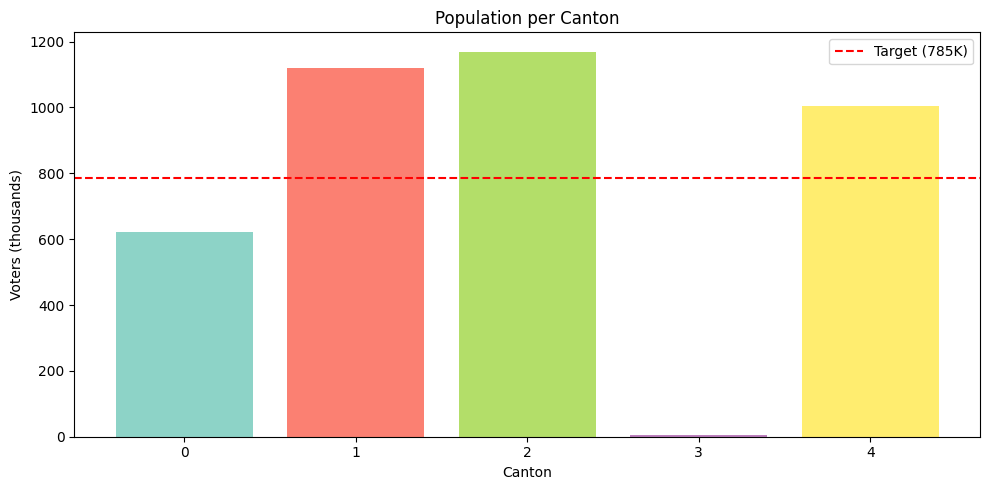

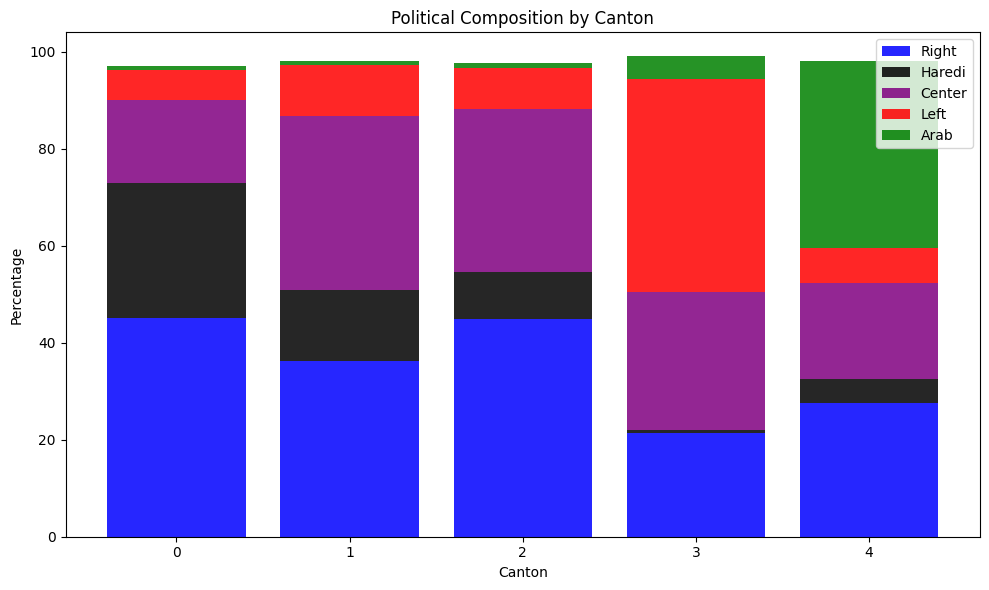

In [7]:
profiles = canton_profiles(assignment, features, weights)
print("Canton Political Profiles:")
print("=" * 100)
print(profiles.to_string(index=False))

# Population balance chart (using src.visualization.charts)
target_voters = sum(weights.values()) / TARGET_K
fig = plot_population_balance(profiles, target=target_voters)
plt.show()

# Political composition stacked bar (using src.visualization.charts)
fig = plot_political_composition(profiles)
plt.show()

## 6. Canton Map

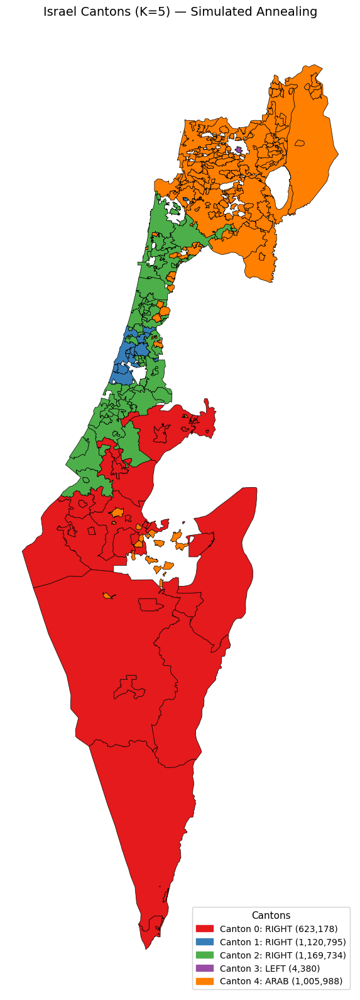

In [8]:
# Load GeoJSON and plot cantons using src.visualization.maps
geo = gpd.read_file(DATA_PROCESSED / 'municipalities_dissolved.geojson')

# Static canton map
fig = plot_cantons(assignment, geo, profiles=profiles,
                   title=f'Israel Cantons (K={assignment.k}) — Simulated Annealing')
plt.show()

# Interactive folium map
m = create_folium_map(assignment, geo, profiles=profiles)
m

## 7. Save Results

In [9]:
# Save assignments
assignment.to_dataframe().to_csv(DATA_PROCESSED / 'cantons_sa_k5.csv', index=False, encoding='utf-8')
print(f"Saved cantons_final.csv ({len(assignment.assignments)} municipalities)")

# Save canton stats
profiles.to_csv(DATA_PROCESSED / 'cantons_sa_k5_stats.csv', index=False, encoding='utf-8')
print(f"Saved cantons_final_stats.csv ({len(profiles)} cantons)")

# Save dissolved canton GeoJSON
geo_save = geo.copy()
geo_save['canton'] = geo_save['MUN_HEB'].map(assignment.assignments)
geo_cantons = geo_save.dropna(subset=['canton']).copy()
geo_cantons['canton'] = geo_cantons['canton'].astype(int)
cantons_geo = geo_cantons.dissolve(by='canton').reset_index()
cantons_geo.to_file(DATA_PROCESSED / 'cantons_sa_k5.geojson', driver='GeoJSON')
print(f"Saved cantons_final.geojson")

# Sample municipalities per canton
print("\nSample municipalities per canton:")
print("=" * 70)
for cid in sorted(set(assignment.assignments.values())):
    members = assignment.get_members(cid)
    p = profiles[profiles['canton'] == cid].iloc[0]
    bloc = p.get('dominant_bloc', '?')
    print(f"\nCanton {cid} ({bloc.upper()}, {len(members)} munis):")
    for m in members[:5]:
        print(f"  - {m}")
    if len(members) > 5:
        print(f"  ... and {len(members) - 5} more")

Saved cantons_final.csv (229 municipalities)
Saved cantons_final_stats.csv (5 cantons)


Saved cantons_final.geojson

Sample municipalities per canton:

Canton 0 (RIGHT, 27 munis):
  - שדות נגב
  - דימונה
  - נתיבות
  - מרחבים
  - אופקים
  ... and 22 more

Canton 1 (RIGHT, 18 munis):
  - בני ברק
  - רכסים
  - קרית יערים
  - אלעד
  - רמת גן
  ... and 13 more

Canton 2 (RIGHT, 62 munis):
  - דאלית אל-כרמל
  - עוספייא
  - חוף השרון
  - נתניה
  - רעננה
  ... and 57 more

Canton 3 (LEFT, 1 munis):
  - בית ג'ן

Canton 4 (ARAB, 121 munis):
  - עראבה
  - נצרת
  - אום אל-פחם
  - סח'נין
  - דבוריה
  ... and 116 more
